<a href="https://colab.research.google.com/github/PearSkyRich/ViT_CIFAR-100/blob/main/Run_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [6]:
class VisionTransformer(nn.Module):

    def __init__(
        self,
        image_size=32,
        patch_size=4,
        num_classes=100,
        embed_dim=192,
        depth=6,
        num_heads=6,
        mlp_dim=384,
        dropout=0.1
    ):
        super(VisionTransformer, self).__init__()

        self.patch_size = patch_size

        # Chuyển ảnh thành các patch
        self.patch_embedding = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        num_patches = (image_size // patch_size) ** 2

        # Class token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional Embedding
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        self.dropout = nn.Dropout(dropout)

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=depth
        )

        self.norm = nn.LayerNorm(embed_dim)

        # Classification Head
        self.head = nn.Linear(embed_dim, num_classes)

        # Khởi tạo tham số
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):

        # Bước 1: Patch Embedding
        x = self.patch_embedding(x)

        # [Batch, Embed_dim, 8, 8]
        x = x.flatten(2)

        # [Batch, 64, Embed_dim]
        x = x.transpose(1, 2)

        # Bước 2: Thêm Class Token
        cls_tokens = self.cls_token.expand(x.shape[0], -1, -1)

        x = torch.cat((cls_tokens, x), dim=1)

        # Bước 3: Thêm Positional Embedding
        x = x + self.pos_embedding

        x = self.dropout(x)

        # Bước 4: Transformer Encoder
        x = self.transformer(x)

        # Bước 5: Lấy đặc trưng từ Class Token
        x = self.norm(x[:, 0])

        # Bước 6: Phân loại
        x = self.head(x)

        return x

In [7]:
model = VisionTransformer().to(device)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/ViT_CIFAR100/best_vit_cifar100.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Đã tải mô hình ViT thành công!")

/tmp/ipykernel_2964/1995245351.py:51: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


Đã tải mô hình ViT thành công!


Vui lòng chọn một hoặc nhiều ảnh để dự đoán:


Saving GDLS-MPF.JPG.webp to GDLS-MPF.JPG (2).webp

--- Đang xử lý ảnh: GDLS-MPF.JPG (2).webp ---


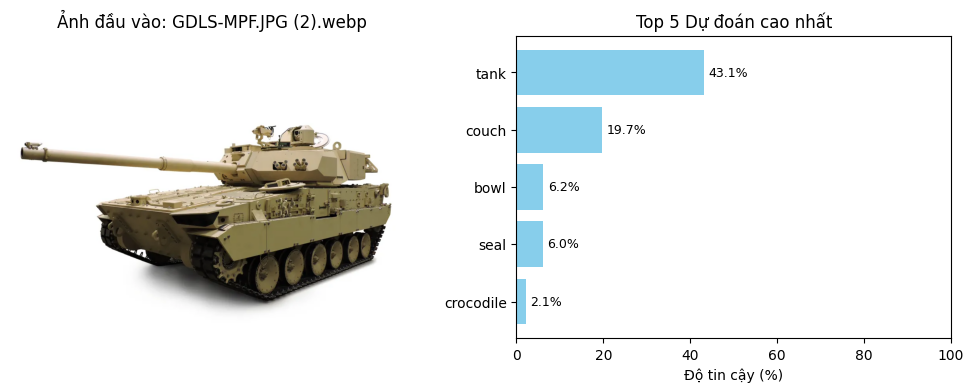

In [8]:
from google.colab import files, drive
import io
import json
import os
import torch
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms



# 1. Kết nối Google Drive nếu chưa kết nối và kiểm tra nhãn class_names
if not os.path.exists("/content/drive"):
    print("Đang kết nối Google Drive...")
    drive.mount("/content/drive")

json_path = "/content/drive/MyDrive/ViT_CIFAR100/cifar100_classes.json"
if 'class_names' not in locals() or class_names is None:
    if os.path.exists(json_path):
        with open(json_path, "r", encoding="utf-8") as f:
            class_names = json.load(f)
        print("Đã tải thành công danh sách nhãn từ Drive.")
    else:
        raise FileNotFoundError("Không tìm thấy file JSON lưu nhãn tại: " + json_path + ". Hãy chắc chắn rằng bạn đã tải file lên đúng thư mục trên Drive!")

# 2. Định nghĩa hàm tiền xử lý ảnh (transforms)
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5071, 0.4867, 0.4408],
        std=[0.2675, 0.2565, 0.2761]
    )
])

# 3. Yêu cầu tải ảnh lên
print("Vui lòng chọn một hoặc nhiều ảnh để dự đoán:")
uploaded = files.upload()

if not uploaded:
    print("Bạn chưa chọn ảnh nào!")
else:
    for fn in uploaded.keys():
        print(f"\n--- Đang xử lý ảnh: {fn} ---")
        # Đọc và chuyển đổi định dạng ảnh
        image_bytes = uploaded[fn]
        image = Image.open(io.BytesIO(image_bytes)).convert("RGB")

        # Chuẩn bị tensor đưa vào mô hình
        input_tensor = transform(image).unsqueeze(0).to(device)

        # Tiến hành dự đoán không tính gradient
        # LƯU Ý: Đảm bảo bạn đã định nghĩa biến `model` ở các cell trước đó
        if 'model' not in locals() and 'model' not in globals():
            raise NameError("Biến 'model' chưa được định nghĩa. Vui lòng tải mô hình của bạn trước khi chạy cell này!")

        with torch.no_grad():
            outputs = model(input_tensor)
            probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]

        # Lấy top 5 dự đoán tốt nhất
        top5_prob, top5_catid = torch.topk(probabilities, 5)

        # Biến đổi định dạng để vẽ đồ thị
        probs = [p.item() * 100 for p in top5_prob]
        labels = [class_names[cid.item()] for cid in top5_catid]

        # Hiển thị trực quan: bên trái là ảnh, bên phải là biểu đồ cột top 5
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

        # Vẽ ảnh gốc
        ax1.imshow(image)
        ax1.set_title(f"Ảnh đầu vào: {fn}")
        ax1.axis("off")

        # Vẽ biểu đồ cột xác suất
        y_pos = range(len(labels))
        bars = ax2.barh(y_pos, probs, align='center', color='skyblue')
        ax2.set_yticks(y_pos)
        ax2.set_yticklabels(labels)
        ax2.invert_yaxis()  # Đảo ngược trục Y để nhãn cao nhất nằm trên cùng
        ax2.set_xlabel('Độ tin cậy (%)')
        ax2.set_title('Top 5 Dự đoán cao nhất')
        ax2.set_xlim(0, 100)

        # Thêm nhãn text ghi phần trăm cụ thể bên cạnh mỗi cột
        for bar in bars:
            width = bar.get_width()
            ax2.text(width + 1, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
                     ha='left', va='center', fontsize=9)

        plt.tight_layout()
        plt.show()